# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [3]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [4]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [5]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

Saved bg_hourly_2019.csv — a row per hour of 2019.


## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

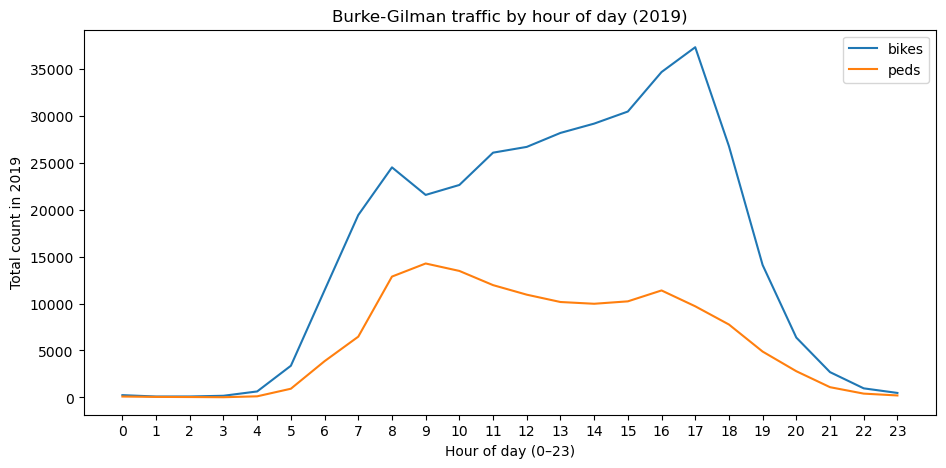

In [6]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

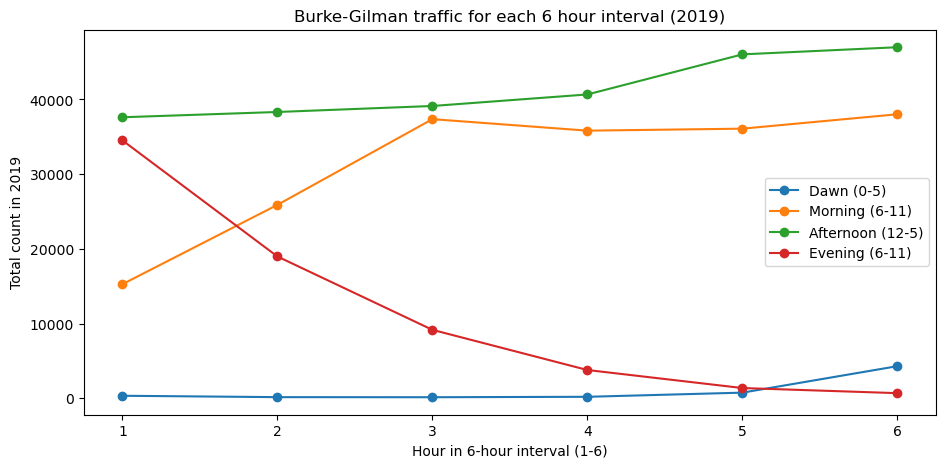

In [7]:
# Your code for Q1 (or put a Google Sheets link in your written answer below)
df["people"] = df["bikes"] + df["peds"] #group peds and bikes together

by_hour = df.groupby("hour")["people"].sum()

by_period = pd.DataFrame({
    "Dawn (0-5)": by_hour.loc[0:5].values,
    "Morning (6-11)": by_hour.loc[6:11].values,
    "Afternoon (12-5)": by_hour.loc[12:17].values,
    "Evening (6-11)": by_hour.loc[18:23].values
}, index=range(1,7))

by_period.plot(figsize=(11, 5), marker="o")

plt.title("Burke-Gilman traffic for each 6 hour interval (2019)")
plt.xlabel("Hour in 6-hour interval (1-6)")
plt.ylabel("Total count in 2019")
plt.xticks(range(1, 7))
plt.show()


**Your Q1 answer:**

*I decided to model when the trail is busiest by using four stretches of a day in 6-hour intervals to identify what stretch of the day is busiest. I combined bikes and pedestrians because they both contribute to how busy or how much traffic the trail has at a certain hour. With the graph, the hour when traffic is busiest is during the afternoon from 12pm-5pm, and when it is quietest during dawn from 0am-5am. This makes sense in context, because most people are sleeping from 0am-5am so they would not be on the trail, and most are would be active 12pm-5pm when the sun is still up and they are , making it the most optimal time to use the trail in comparison to the morning or evening*

***AI Prompt**: How do I show 6-hour intervals on a plot using panda for jupyter notebook if I have by_hour = df.groundpy("hour")["people"].sum()*

***AI Original Output:***

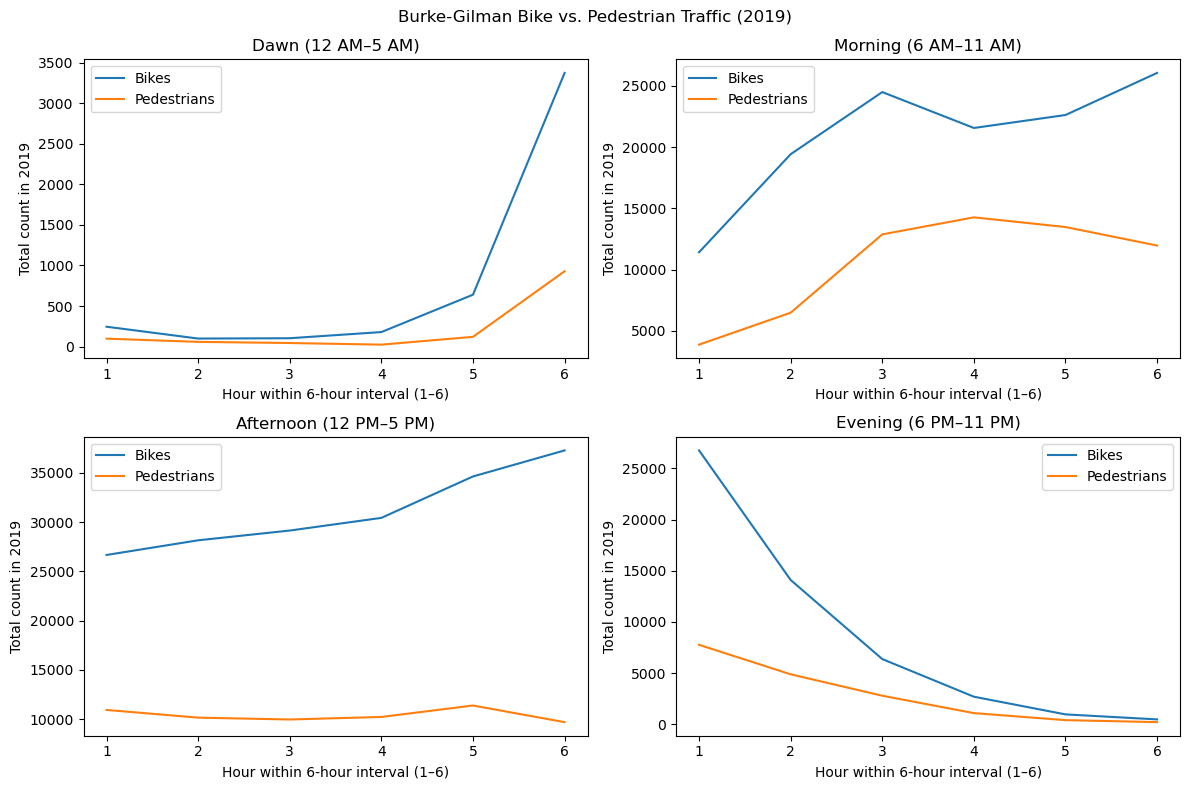

In [8]:
# Group bikes and pedestrians by hour
by_bikes = df.groupby("hour")["bikes"].sum()
by_peds = df.groupby("hour")["peds"].sum()

# Split into four 6-hour intervals
periods = {
    "Dawn (12 AM–5 AM)": (by_bikes.loc[0:5], by_peds.loc[0:5]),
    "Morning (6 AM–11 AM)": (by_bikes.loc[6:11], by_peds.loc[6:11]),
    "Afternoon (12 PM–5 PM)": (by_bikes.loc[12:17], by_peds.loc[12:17]),
    "Evening (6 PM–11 PM)": (by_bikes.loc[18:23], by_peds.loc[18:23])
}

# Create four plots in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (title, (bikes, peds)) in zip(axes.flat, periods.items()):
    # Use positions 1–6 for each interval
    ax.plot(range(1, 7), bikes.values, label="Bikes")
    ax.plot(range(1, 7), peds.values, label="Pedestrians")

    ax.set_title(title)
    ax.set_xlabel("Hour within 6-hour interval (1–6)")
    ax.set_ylabel("Total count in 2019")
    ax.set_xticks(range(1, 7))
    ax.legend()

fig.suptitle("Burke-Gilman Bike vs. Pedestrian Traffic (2019)")
plt.tight_layout()
plt.show()

***What I changed:** I labeled the intervals to show the corresponding hours so that it would be easier to understand the time the intervals take place in*

---

#### **Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

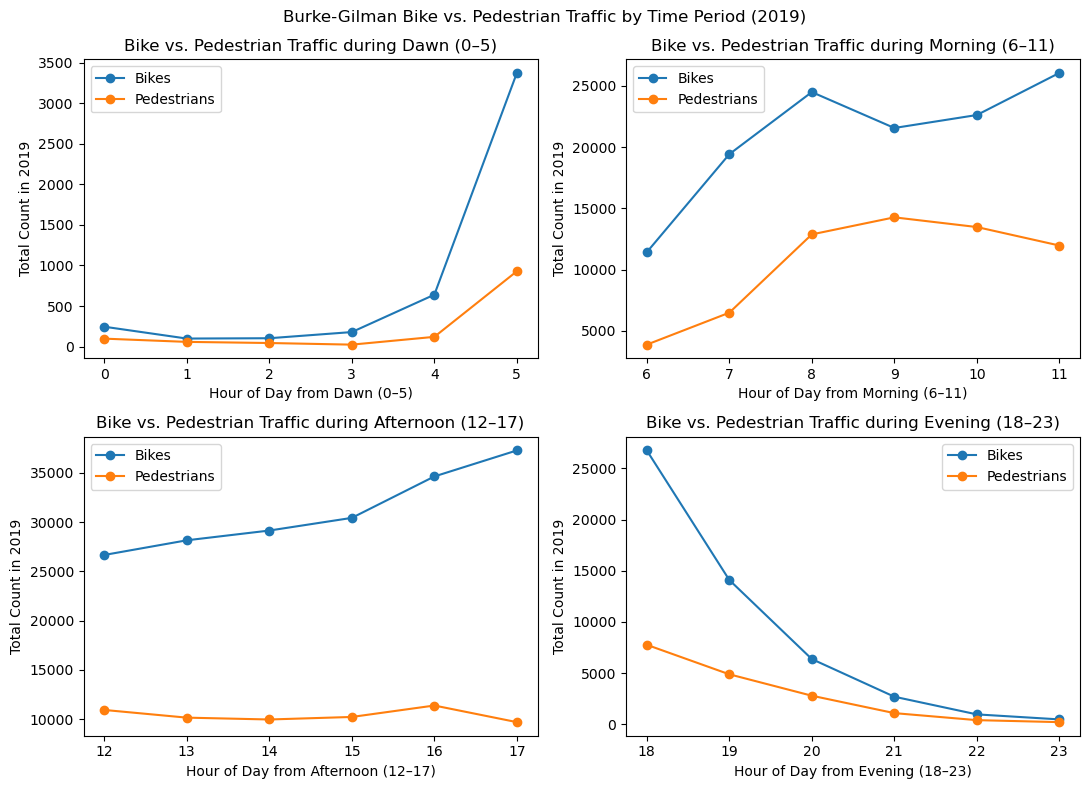

In [9]:
# Your code for Q2
by_bikes = df.groupby("hour")["bikes"].sum()
by_peds = df.groupby("hour")["peds"].sum()

periods = {
    "Dawn (0–5)": (0, 5),
    "Morning (6–11)": (6, 11),
    "Afternoon (12–17)": (12, 17),
    "Evening (18–23)": (18, 23)
}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (title, (start, end)) in zip(axes.flat, periods.items()):
    hours = range(start, end + 1)

    ax.plot(hours, by_bikes.loc[start:end], marker="o", label="Bikes")
    ax.plot(hours, by_peds.loc[start:end], marker="o", label="Pedestrians")

    ax.set_title("Bike vs. Pedestrian Traffic during " + title)
    ax.set_xlabel("Hour of Day from " + title)
    ax.set_ylabel("Total Count in 2019")
    ax.set_xticks(list(hours))
    ax.legend()

fig.suptitle("Burke-Gilman Bike vs. Pedestrian Traffic by Time Period (2019)")
plt.tight_layout()
plt.show()

**Your Q2 answer:**

*For this graph, I split it up into 4 subplots to help visualize the comparisons of cyclists vs. pedestrians for each stretch of time. From the graphs, it seems that both  are mostly both active at the same time, but there are more cyclists using the trail than pedestrians. My hypothesis is perhaps that the Burke-Gillman trail is cyclist-friendly, and there could be other routes pedestrians are using instead.*

***AI Prompt:** Based on previous prompt, show me how I could split these periods for "bike" vs "peds" to make 4 plots and show each interval of time. How can I make the x ticks correlate with the hour?*

***AI Original Output:***

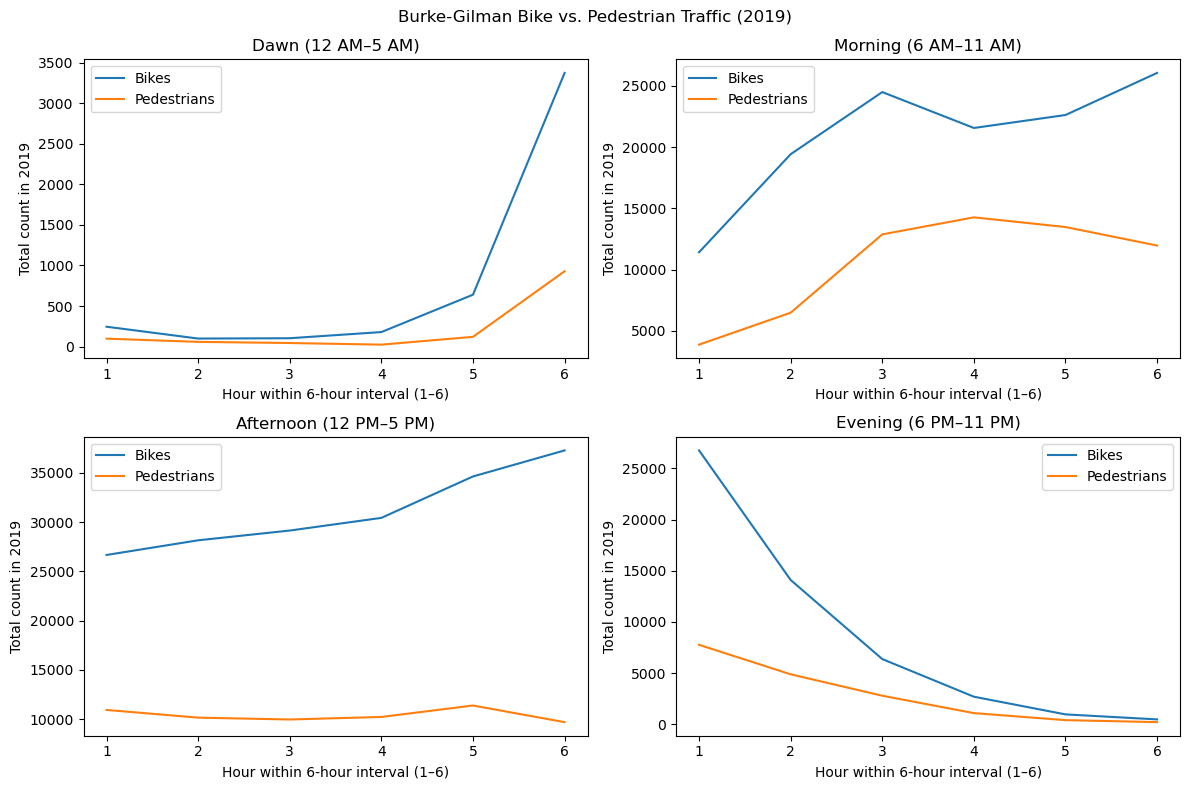

In [10]:
# Group bikes and pedestrians by hour
by_bikes = df.groupby("hour")["bikes"].sum()
by_peds = df.groupby("hour")["peds"].sum()

# Split into four 6-hour intervals
periods = {
    "Dawn (12 AM–5 AM)": (by_bikes.loc[0:5], by_peds.loc[0:5]),
    "Morning (6 AM–11 AM)": (by_bikes.loc[6:11], by_peds.loc[6:11]),
    "Afternoon (12 PM–5 PM)": (by_bikes.loc[12:17], by_peds.loc[12:17]),
    "Evening (6 PM–11 PM)": (by_bikes.loc[18:23], by_peds.loc[18:23])
}

# Create four plots in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (title, (bikes, peds)) in zip(axes.flat, periods.items()):
    # Use positions 1–6 for each interval
    ax.plot(range(1, 7), bikes.values, label="Bikes")
    ax.plot(range(1, 7), peds.values, label="Pedestrians")

    ax.set_title(title)
    ax.set_xlabel("Hour within 6-hour interval (1–6)")
    ax.set_ylabel("Total count in 2019")
    ax.set_xticks(range(1, 7))
    ax.legend()

fig.suptitle("Burke-Gilman Bike vs. Pedestrian Traffic (2019)")
plt.tight_layout()
plt.show()


***What I changed:** I adjusted the titles to accurately describe each line in the chart and also added the correct hours to the x-axis to show the range*


#### **Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

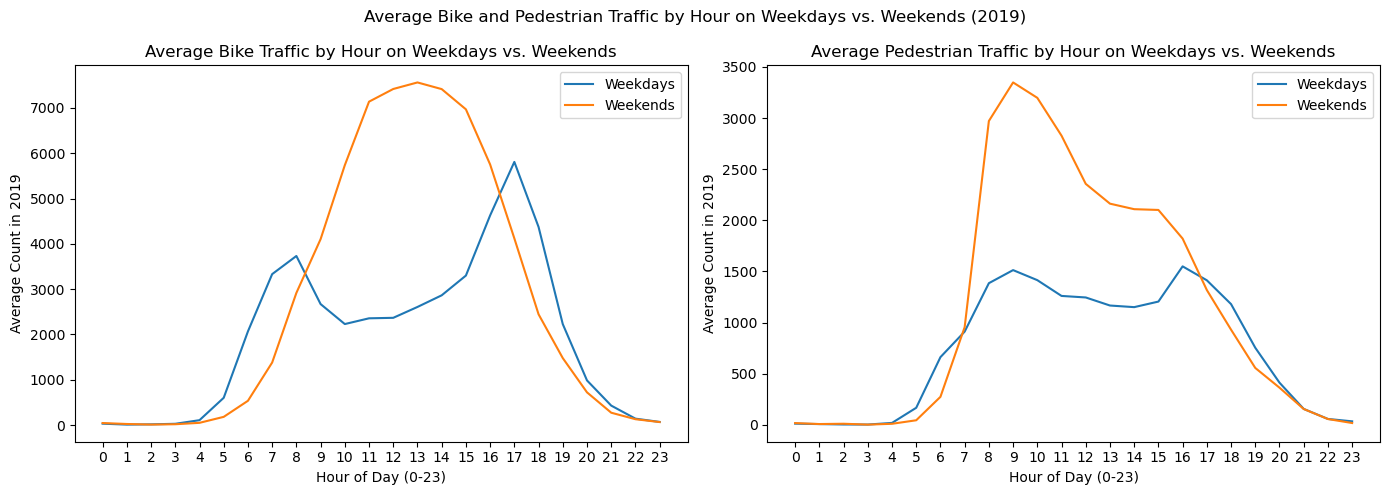

In [11]:
#Your code for Q3 

# Separate weekdays and weekends
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekends = ["Saturday", "Sunday"]

weekday_data = df[df["weekday"].isin(weekdays)]
weekend_data = df[df["weekday"].isin(weekends)]

# Group by hour and calculate average traffic per day of the week
bikes_weekday = weekday_data.groupby(["weekday", "hour"])["bikes"].sum().groupby("hour").mean()
bikes_weekend = weekend_data.groupby(["weekday", "hour"])["bikes"].sum().groupby("hour").mean()

peds_weekday = weekday_data.groupby(["weekday", "hour"])["peds"].sum().groupby("hour").mean()
peds_weekend = weekend_data.groupby(["weekday", "hour"])["peds"].sum().groupby("hour").mean()

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(bikes_weekday.index, bikes_weekday.values, label="Weekdays")
axes[0].plot(bikes_weekend.index, bikes_weekend.values, label="Weekends")
axes[0].set_title("Average Bike Traffic by Hour on Weekdays vs. Weekends")
axes[0].set_xlabel("Hour of Day (0-23)")
axes[0].set_ylabel("Average Count in 2019")
axes[0].set_xticks(range(24))
axes[0].legend()

axes[1].plot(peds_weekday.index, peds_weekday.values, label="Weekdays")
axes[1].plot(peds_weekend.index, peds_weekend.values, label="Weekends")
axes[1].set_title("Average Pedestrian Traffic by Hour on Weekdays vs. Weekends")
axes[1].set_xlabel("Hour of Day (0-23)")
axes[1].set_ylabel("Average Count in 2019")
axes[1].set_xticks(range(24))
axes[1].legend()


fig.suptitle("Average Bike and Pedestrian Traffic by Hour on Weekdays vs. Weekends (2019)")
plt.tight_layout()
plt.show()

**Your Q3 answer:**

*Based on the graph, there is more traffic on the weekend compared to weekdays. The "commuting pattern" that is shown tells us that cyclists and pedestrians use the trail for commuting on the weekdays, due to the peak in activity during the morning and during the evening, and use the trail for fun on the weekends because of the sustained traffic in the afternoon. The differences in cyclist and pedestrian traffic on weekends also show that pedestrians are using the trail for morning walks while cyclists tend to use it throughout the day.*

***AI Prompt:** How could I compare bikes and pedestrians by weekday vs. weekends by hour? There is a weekday variable that shows strings of the week*

***AI Original Output:***

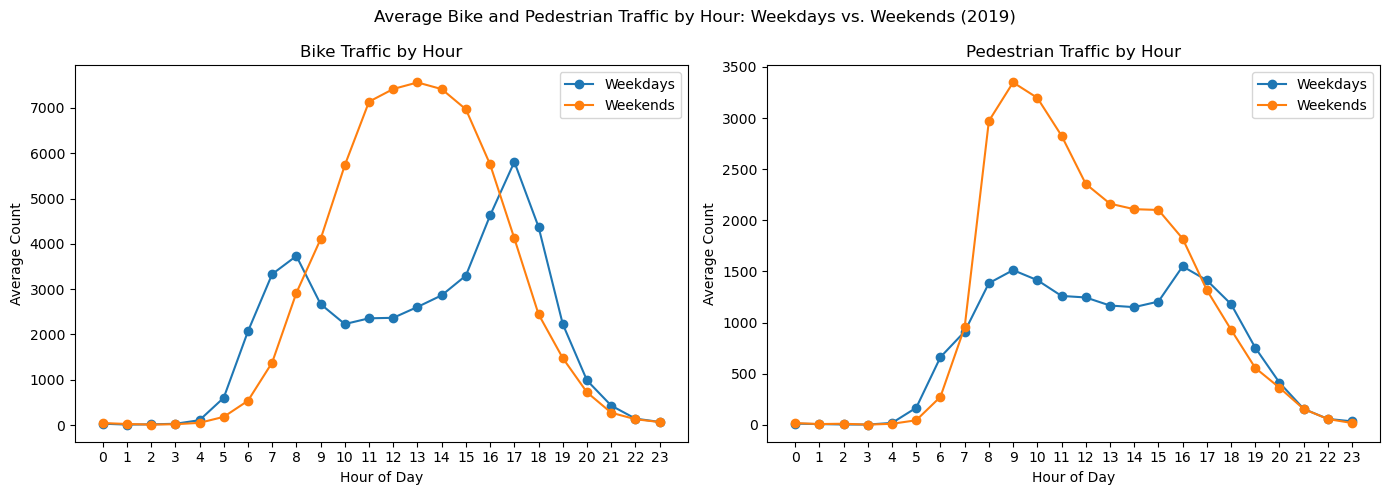

In [12]:
# Separate weekdays and weekends
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
weekends = ["Saturday", "Sunday"]

weekday_data = df[df["weekday"].isin(weekdays)]
weekend_data = df[df["weekday"].isin(weekends)]

# Group by hour and calculate average traffic per day of the week
bikes_weekday = weekday_data.groupby(["weekday", "hour"])["bikes"].sum().groupby("hour").mean()
bikes_weekend = weekend_data.groupby(["weekday", "hour"])["bikes"].sum().groupby("hour").mean()

peds_weekday = weekday_data.groupby(["weekday", "hour"])["peds"].sum().groupby("hour").mean()
peds_weekend = weekend_data.groupby(["weekday", "hour"])["peds"].sum().groupby("hour").mean()

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(bikes_weekday.index, bikes_weekday.values, marker="o", label="Weekdays")
axes[0].plot(bikes_weekend.index, bikes_weekend.values, marker="o", label="Weekends")
axes[0].set_title("Bike Traffic by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Average Count")
axes[0].set_xticks(range(24))
axes[0].legend()

axes[1].plot(peds_weekday.index, peds_weekday.values, marker="o", label="Weekdays")
axes[1].plot(peds_weekend.index, peds_weekend.values, marker="o", label="Weekends")
axes[1].set_title("Pedestrian Traffic by Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Average Count")
axes[1].set_xticks(range(24))
axes[1].legend()

fig.suptitle("Average Bike and Pedestrian Traffic by Hour: Weekdays vs. Weekends (2019)")
plt.tight_layout()
plt.show()

***What I changed:** I adjusted the titles for the graphs to be more accurate and specific to what data is being shown in each plot so that it was easier to understand what is being graphed. It originally only wrote "Bike/Pedestrian Traffic by Hour" and didn't specify the year or the range of hours in the axes titles. I also removed the dots on each hour to make it look cleaner.* 

#### **Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

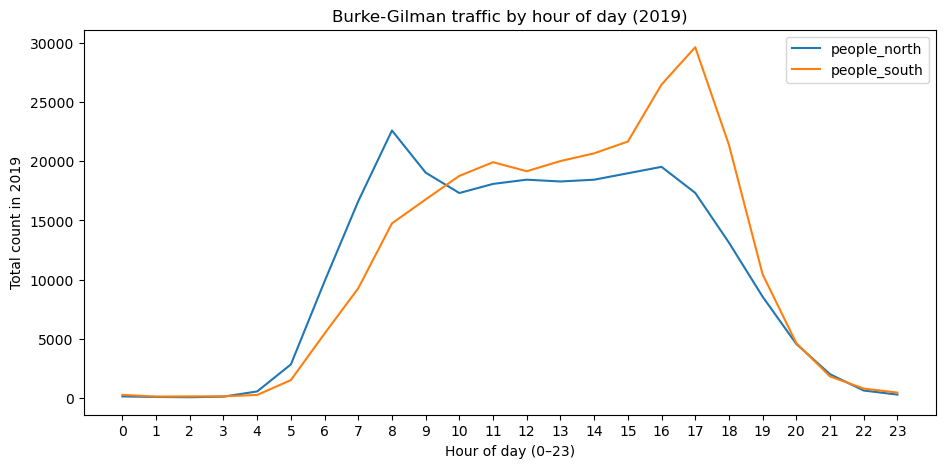

In [28]:
# Your code for Q4
df["people_north"] = df["bike_north"] + df["ped_north"]
df["people_south"] = df["bike_south"] + df["ped_south"]

by_time = df.groupby("hour")[["people_north", "people_south"]].sum()

by_time.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Your Q4 answer:**

*Based on the graph, it seems that more people are going north in the morning and more people are going south in the evening. I combined both cyclists and pedestrians again to see where the overall traffic was coming from. By looking up the map of the Burke-Gilman trail, the south is near the University of Washington and the north is near Bothell, where it also seems that there are a lot of parks north of the trail. I hypothesize that the majority of people using the trail are people living near the University of Washington are heading up north to go to these parks and return back home during the evening.*

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

*One bias this dataset could have that could mislead someone is if the people on the trail went back and forth on the trail multiple times. This could skew the data to have higher counts for cyclists or pedestrians in the set than there were in reality. This could mislead someone into thinking that more cyclists are using the path than there are and make wrong conclusions.

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.